# 2. Per-event data: the geometry is never touched

A chamber is static; an event is a table of numbers on its cells. The contract
is one table keyed by `(sl, l, w)` plus the columns you want to colour by:

```
rows = [{"sl": 1, "l": 1, "w": 1, "time": 350}, ...]
DTStationPatch(station, axis, vmap="time", data=rows)
```

`vmap` names the column to map: it is `"time"` by default, and any column works.
Because nothing is written on the geometry, the same `Station` object draws two
events in a row.

In [1]:
%matplotlib inline
import random

from mpldts.geometry import Station
from mpldts.geometry.sources import CMSXMLSource

spec = CMSXMLSource().station(-2, 1, 2)
station = Station.from_spec(spec, -2, 1, 2)

def event(seed, low=200, high=900):
    # one row per cell: a random drift time, as a digitised event would give
    generator = random.Random(seed)
    return [
        {"sl": sl.number, "l": layer.number, "w": wid,
         "time": generator.randint(low, high)}
        for sl in spec.super_layers
        for layer in sl.layers
        for wid in layer.cells.ids()
    ]

first = event(1)
print(len(first), "rows,", len({(r["sl"], r["l"]) for r in first}), "layers")
first[:3]

704 rows, 12 layers


[{'sl': 1, 'l': 1, 'w': 1, 'time': 337},
 {'sl': 1, 'l': 1, 'w': 2, 'time': 782},
 {'sl': 1, 'l': 1, 'w': 3, 'time': 264}]

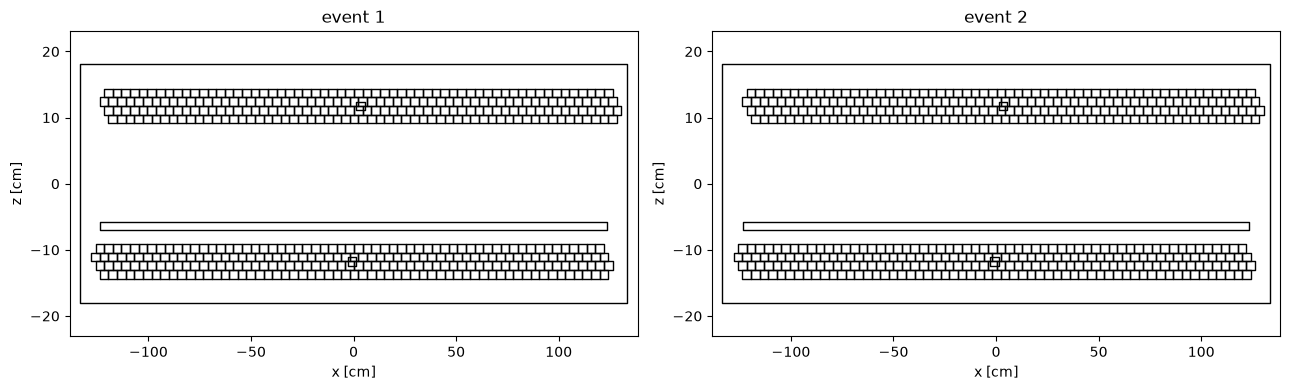

In [2]:
import matplotlib.pyplot as plt
from mpldts.patches import DTStationPatch

width, height, length = station.bounds
x, y, z = station.local_center

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, rows, title in zip(axes, (first, event(2)), ("event 1", "event 2")):
    DTStationPatch(station, axis, faceview="phi", local=True, vmap="time", data=rows)
    axis.set_xlim(x - width / 2 - 5, x + width / 2 + 5)
    axis.set_ylim(z - height / 2 - 5, z + height / 2 + 5)
    axis.set_title(title)
    axis.set_xlabel("x [cm]")
    axis.set_ylabel("z [cm]")
figure.tight_layout()

The station was built once and used twice. Its own values are unchanged, which
is the point of the contract: geometry in, data on the side.

In [3]:
after = Station.from_spec(spec, -2, 1, 2)
import numpy as np
print("same centre:", bool(np.allclose(station.local_center, after.local_center)))
print("cells in the view:", sum(len(layer.cells) for sl in station.super_layers
                               for layer in sl.layers))

same centre: True
cells in the view: 704


## More than one column: `change_vmap`

An event usually carries several quantities (`time`, `width`, a digitised
charge...). `change_vmap` re-colours the same patch from the same rows.

vmap: width | values: 704


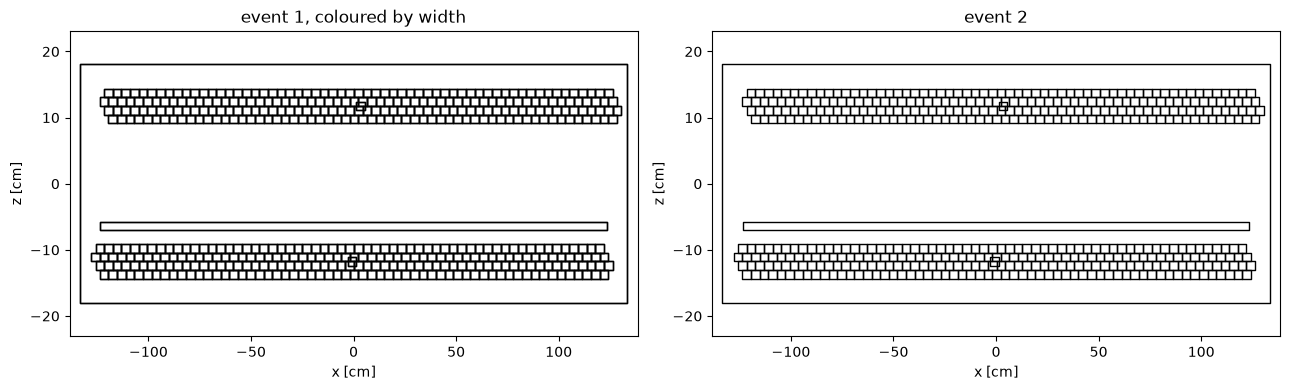

In [4]:
patch = DTStationPatch(station, axes[0], faceview="phi", local=True, vmap="time",
                       data=[dict(row, width=row["time"] / 100.0) for row in first])
patch.change_vmap("width")
print("vmap:", patch.vmap, "| values:", len(patch.values))
axes[0].set_title("event 1, coloured by width")
figure

## A DataFrame from a ROOT ntuple or a CSV

Anything with `to_dict` is accepted: a pandas DataFrame, one dict, or a list of
dicts. The identifiers are cast to `int` for you, because a branch read from a
ROOT file arrives as a float and `(1.0, 2.0, 3.0)` would never match a cell.

In [5]:
import pandas as pd

frame = pd.DataFrame(first)
frame[["sl", "l", "w"]] = frame[["sl", "l", "w"]].astype(float)   # as ROOT gives them
print({key: str(kind) for key, kind in frame.dtypes[["sl", "l", "w"]].items()})

patch = DTStationPatch(station, axes[1], faceview="phi", local=True,
                       vmap="time", data=frame)
print("rows accepted:", len(patch.data), "| int cast:", patch.data[0])

{'sl': 'float64', 'l': 'float64', 'w': 'float64'}


rows accepted: 704 | int cast: {'sl': 1, 'l': 1, 'w': 1, 'time': 337}


## The rules, in short

- keyed by `(sl, l, w)`; the ids are integers and the patch casts them;
- `vmap` selects the column, `time` by default;
- a cell that is not in the table simply draws at 0;
- nothing mutates the station: two events, one geometry.

The next notebook writes a detector that is not in the CMS file at all.